In [1]:
import matplotlib.pyplot as plt
import time
import torch
import numpy as np
from sympy.codegen.rewriting import Optimization
from tqdm import tqdm
from tqdm.notebook import tqdm
import pandas as pd
import torch
import os
from datetime import datetime
import sys
import json
from tqdm import trange
from functools import partial

In [2]:
# Check if running in Google Colab
if 'google.colab' in str(get_ipython()):
    import getpass
    !pip install flow_matching

    # Prompt the user for their GitHub personal access token (hidden input)
    # token = getpass.getpass("Enter your GitHub personal access token: ")
    token=os.environ["GITHUB_TOKEN"]
    repo_url = f"https://{token}@github.com/orineo1/GlobalConditional.git"
    repo_name = "GlobalConditional"

    # Clone the repository
    if not os.path.exists(repo_name):
        !git clone {repo_url}
    branch_name = "AddingSuperposition"
    !cd {repo_name} && git checkout {branch_name}

    # Add the repository to Python path
    sys.path.append(f"/content/{repo_name}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.7/48.7 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 90.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 70.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 42.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 35.1 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling

In [3]:
import importlib
import Diffusion
import DiffusionGeneral
import superposition_utils

import LossFunctions
import ConsistencyModels
import  FlowMatching
from ConsistencyModels import ConsistencyModel
import dist_utils
import Optimization

importlib.reload(Diffusion)
importlib.reload(LossFunctions)
importlib.reload(ConsistencyModels)
importlib.reload(FlowMatching)
importlib.reload(dist_utils)
importlib.reload(Optimization)
importlib.reload(superposition_utils)
importlib.reload(DiffusionGeneral)



<module 'DiffusionGeneral' from '/content/GlobalConditional/DiffusionGeneral.py'>

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cpu


# 10D cond on 9D

In [5]:
## NN
nblocks=5
nunits=128
nepochs=30_000
batch_size=512



## Diffusion
diffusion_steps=100

## Optimization
n_attemp_optim=25
nsamples_in_optim_for_mmd=250

In [6]:
mu_list, Sigma_list, alpha,mog_means, mog_variances,weights,x_star= dist_utils.get_param_mog_with_target(dim_data=10,num_components=4,device='cpu',conditional_modes=2,distanceOrScale="Distance")
mog_means, mog_variances, weights= dist_utils.filter_and_normalize(mog_means, mog_variances, weights, threshold=0.001)


/content/GlobalConditional/dist_utils.py:412: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:3725.)
  exponent = -0.5 * diff.T @ Sigma_22_inv @ diff


## Consistency Models

In [7]:
## LGD
# init a model, train
X = dist_utils.generate_mog_samples(1_000, mu_list, Sigma_list, alpha).float().to(device)

condition_on=9
B, C = X.shape
nfeatures = C - condition_on

Cos_model = ConsistencyModel(nfeatures=nfeatures, condition_on=condition_on, nunits=128)
Cos_model.train_model(X=None, nepochs=nepochs
                      ,batch_size=256, device= "cpu", condition=condition_on,
                      data_generator=partial(dist_utils.generate_mog_samples, xi=mu_list, S=Sigma_list, beta=alpha, kernel_func=None),
                      )

loss: 0.003123, mu: 0.9993: 100%|██████████| 30000/30000 [29:13<00:00, 17.11it/s]


## SuperPosition

### Train

In [8]:
# Flip the values for superposition
point_l = [p.flip(0) for p in mu_list]
mu_list_super = point_l
idx = torch.arange(Sigma_list[0].size(0) - 1, -1, -1)
Sigma_list_super = [s[idx][:, idx]  for s in Sigma_list]# [.T for sigma in Sigma_list]


nfeatures= mu_list[0].shape[0]
condition_on=1

# Train
model_cond_diff =DiffusionGeneral.DiffusionModel(nfeatures=nfeatures, nblocks=nblocks, nunits=nunits, condition=True,condition_on=condition_on,diffusion_steps=diffusion_steps)
model_cond_diff.train_model( data_generator=partial(dist_utils.generate_mog_samples, xi=mu_list_super, S=Sigma_list_super, beta=alpha, kernel_func=None),dataloader=None, num_iterations=nepochs)


100%|██████████| 30000/30000 [37:09<00:00, 13.45it/s, loss=0.525]


### Optimize

In [9]:
n_sample=n_attemp_optim
first_value = mog_means[0].item()
second_value = mog_means[1].item()
cond1= torch.tensor([first_value],device=device)
cond2= torch.tensor([second_value],device=device)
cond3= torch.tensor([first_value+0.2],device=device)

start_time = time.time()
cond_l= [cond1,cond2,cond3]
x_gen_iso,_=  superposition_utils.generate_isosurface_samples(model_cond_diff, cond_l=cond_l,bs=n_sample,device=device)
X_gen_np = x_gen_iso[:, -1, :].detach().cpu().numpy()
end_time = time.time()


superposition_times_cond3 = [end_time - start_time] *n_attemp_optim


# Flip again
X_gen_np_original = torch.tensor(X_gen_np)[:,condition_on:]
X_gen_np_original=X_gen_np_original.flip(1)


  0%|          | 0/1000 [00:00<?, ?it/s]

[tensor([[ -1.2472],
        [  3.0537],
        [  1.8773],
        [-11.0526],
        [  5.1591],
        [  2.4975],
        [  3.7282],
        [ -2.1743],
        [ -3.2832]]), tensor([[-2.6589],
        [ 3.1712],
        [-1.3879],
        [-8.6950],
        [ 2.2478],
        [-2.3317],
        [-1.8463],
        [-5.6189],
        [-8.8646]]), tensor([[-2.4107],
        [ 4.0278],
        [ 7.8012],
        [-9.7238],
        [ 1.4098],
        [-4.7602],
        [ 5.4330],
        [-0.8765],
        [-8.9385]]), tensor([[ -2.9279],
        [  6.1967],
        [  0.2590],
        [-13.3188],
        [  4.7334],
        [ -0.8804],
        [ -1.8732],
        [ -1.7452],
        [  0.3630]]), tensor([[ -5.3431],
        [ -2.7956],
        [  0.3676],
        [ -7.5474],
        [  1.4722],
        [  1.3487],
        [  3.7055],
        [ -0.9474],
        [-10.9526]]), tensor([[-5.2064],
        [ 0.1386],
        [-3.1534],
        [-8.7236],
        [ 1.9712],
        [ 0.

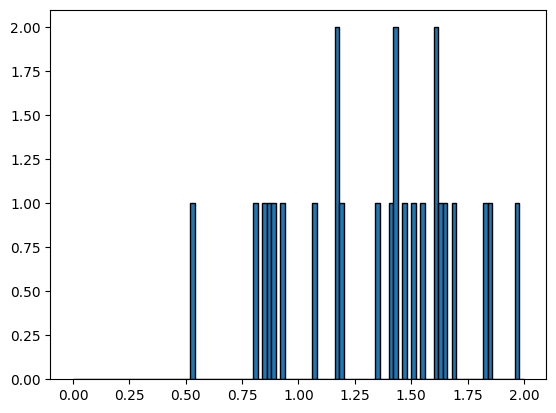

In [10]:
best_x_t_superposition_list_cond3=[]
l1_distance_superposition_list_3cond=[]
for i in range(X_gen_np_original.shape[0]):
   val = X_gen_np_original[i:i+1].reshape(-1, 1)
   l1_distance = dist_utils.warpper_L1_distance(val, mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
   l1_distance_superposition_list_3cond.append(l1_distance )
   best_x_t_superposition_list_cond3.append(val)


print(best_x_t_superposition_list_cond3)
print(l1_distance_superposition_list_3cond)

plt.hist(l1_distance_superposition_list_3cond,  edgecolor='black',range=(0,2),bins=100,)
plt.show()


In [11]:
superposition_times=superposition_times_cond3
l1_distance_superposition_list=l1_distance_superposition_list_3cond
best_x_t_superposition_list=l1_distance_superposition_list_3cond

## LGD

### Train

In [12]:

nfeatures = X.shape[1]
condition_on = mu_list[0].shape[0] - mog_means[0].shape[0]
model_cond = Diffusion.DiffusionModel(nfeatures=nfeatures, nblocks=nblocks, nunits=nunits, condition=True,
                                      condition_on=condition_on, diffusion_steps=diffusion_steps)
losses = model_cond.train_model(X,
                                data_generator=partial(dist_utils.generate_mog_samples, xi=mu_list, S=Sigma_list, beta=alpha, kernel_func=None),
                                nepochs=nepochs, batch_size=batch_size, condition_on=condition_on)

loss: 0.171371: 100%|██████████| 30000/30000 [37:56<00:00, 13.18it/s]


In [13]:
# init a model, train
X_for_cond_only = X[:, :model_cond.condition_on]
nfeatures = X_for_cond_only.shape[1]


model_uncond=Diffusion.DiffusionModel(nfeatures=nfeatures, nblocks=nblocks, nunits=nunits, condition=False,diffusion_steps=diffusion_steps)
losses = model_uncond.train_model(X_for_cond_only,
                                  data_generator=partial(dist_utils.generate_mog_samples, xi=mu_list, S=Sigma_list, beta=alpha,kernel_func=lambda X: X[:, :model_cond.condition_on]),
                                  nepochs=nepochs
, batch_size=batch_size, condition_on=condition_on)


loss: 0.675242: 100%|██████████| 30000/30000 [35:12<00:00, 14.20it/s]


### Optimize

#### Regular

100%|██████████| 25/25 [3:27:54<00:00, 498.97s/it]


[tensor([[ -4.2343],
        [  3.6923],
        [ -1.1064],
        [-11.7100],
        [  4.5649],
        [  2.0542],
        [  4.7474],
        [ -1.5878],
        [ -4.2183]]), tensor([[19.5241],
        [-5.9667],
        [15.3215],
        [-3.0121],
        [-2.3444],
        [ 8.5682],
        [ 3.8211],
        [23.7353],
        [ 8.5170]]), tensor([[23.1158],
        [-7.7673],
        [13.4894],
        [ 4.1289],
        [-1.8443],
        [ 9.4476],
        [ 1.5710],
        [19.3032],
        [ 6.1810]]), tensor([[ 2.1478e+01],
        [-8.5812e+00],
        [ 5.6541e+00],
        [ 9.1549e+00],
        [-1.9415e-02],
        [ 6.1036e+00],
        [-2.5900e+00],
        [ 1.4098e+01],
        [ 5.5948e-01]]), tensor([[ 23.5316],
        [-11.7997],
        [ 12.0922],
        [  7.4949],
        [ -1.7043],
        [  9.4335],
        [  0.5650],
        [ 17.6749],
        [  5.1987]]), tensor([[ -1.4806],
        [ -5.4987],
        [ -5.7436],
        [  3.8627],


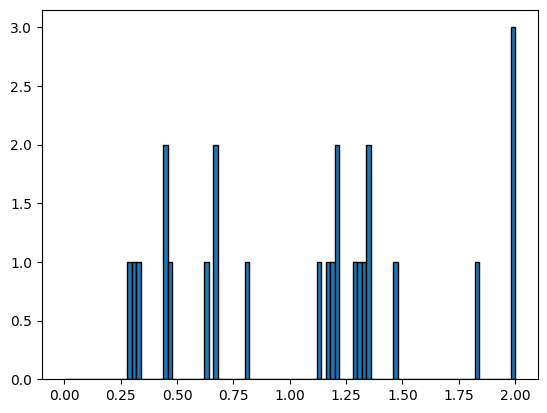

In [14]:
best_x_t_LGD_list=[]
l1_distance_LGD_list=[]
lgd_times = []
for i in trange(n_attemp_optim):
    start_time = time.time()
    best_x_t, best_x_0_cont_xt_hat, best_mmd_loss = Optimization.optimize_LGD(model_uncond, model_cond, mog_means, mog_variances, weights, mu_list, Sigma_list, alpha, nsamples=nsamples_in_optim_for_mmd, loss="MMD", device=device)
    best_x_t=best_x_t.reshape(-1,1)
    end_time = time.time()
    lgd_times.append(end_time - start_time)

    best_x_t_LGD_list.append(best_x_t)
    l1_distance = dist_utils.warpper_L1_distance(best_x_t, mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
    l1_distance_LGD_list.append(l1_distance)

print(best_x_t_LGD_list)
print(l1_distance_LGD_list)

plt.hist(l1_distance_LGD_list,  edgecolor='black',range=(0,2),bins=100,)
plt.show()

### Optimize

#### CM

100%|██████████| 25/25 [15:15<00:00, 36.64s/it]


[tensor([[ -6.9361],
        [  0.9311],
        [  2.7106],
        [-10.0015],
        [  3.1686],
        [  2.8736],
        [ -1.5172],
        [ -3.8389],
        [ -5.5069]]), tensor([[-5.0405],
        [ 1.4846],
        [ 0.6614],
        [-8.3976],
        [ 2.7917],
        [ 3.0382],
        [ 2.5619],
        [-1.1493],
        [-6.1554]]), tensor([[-9.7773],
        [-0.6875],
        [ 2.1419],
        [-2.7274],
        [ 2.1391],
        [ 6.8671],
        [ 3.9853],
        [-5.6553],
        [-2.9504]]), tensor([[ -1.5801],
        [ -1.2566],
        [ -0.9834],
        [  4.5444],
        [  0.0366],
        [ -1.7622],
        [ -1.2742],
        [  4.1019],
        [-14.2183]]), tensor([[ -5.4958],
        [  2.5957],
        [ -0.5928],
        [-10.4216],
        [  4.9595],
        [  2.7010],
        [  6.2413],
        [ -1.6957],
        [ -4.7671]]), tensor([[-4.6993],
        [ 1.9635],
        [ 0.7042],
        [-8.9468],
        [ 3.2462],
        [ 2.

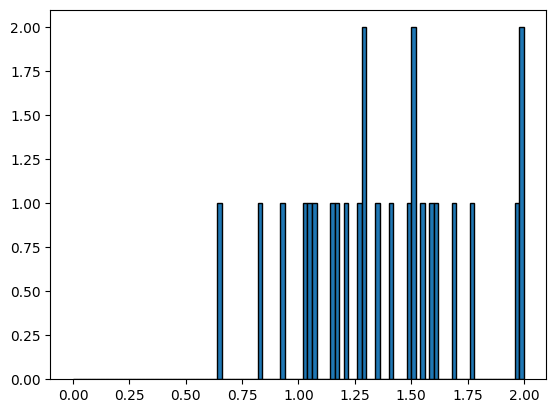

In [15]:
best_x_t_LGD_CM_list=[]
l1_distance_LGD_CM_list=[]
# For LGD_CM timing
lgd_cm_times = []
for i in trange(n_attemp_optim):
    start_time = time.time()
    best_x_t, best_x_0_cont_xt_hat, best_mmd_loss = Optimization.optimize_LGD(model_uncond, Cos_model, mog_means, mog_variances, weights, mu_list, Sigma_list, alpha, nsamples=nsamples_in_optim_for_mmd, loss="MMD", device=device, CM=True, FLAG=False)
    best_x_t=best_x_t.reshape(-1,1)
    end_time = time.time()
    lgd_cm_times.append(end_time - start_time)

    best_x_t_LGD_CM_list.append(best_x_t)
    l1_distance = dist_utils.warpper_L1_distance(best_x_t, mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
    l1_distance_LGD_CM_list.append(l1_distance)

print(best_x_t_LGD_CM_list)
print(l1_distance_LGD_CM_list)


plt.hist(l1_distance_LGD_CM_list,  edgecolor='black',range=(0,2),bins=100,)
plt.show()



## Flow

### Train

In [16]:
input_dim =mog_means[0].shape[0]
y_dim = mu_list[0].shape[0]-mog_means[0].shape[0]
hidden_dim = nunits
depth = nblocks


In [17]:

vf_y_cond_x = FlowMatching.FMModel(nfeatures=input_dim,
                                   condition_on=y_dim,
                                   nunits=hidden_dim,
                                   nblocks=depth,
                                   device=device)
vf_y_cond_x.train_FM(lr=0.001, batch_size=batch_size, X=X, nepochs=nepochs,
                                                        data_generator=partial(dist_utils.generate_mog_samples, xi=mu_list, S=Sigma_list, beta=alpha, kernel_func=None)
                     )


loss: 0.659102: 100%|██████████| 30000/30000 [41:24<00:00, 12.07it/s]


In [18]:
first_column_x=X[:,:y_dim]#print()#print()
input_dim = first_column_x.shape[1]
vf_X = FlowMatching.FMModel(nfeatures=input_dim,
                                   condition_on=0,
                                   nunits=hidden_dim,
                                   nblocks=depth,
                                   device=device)
vf_X.train_FM(lr=0.001, batch_size=batch_size, X=first_column_x, nepochs=nepochs,
                                                                      data_generator=partial(dist_utils.generate_mog_samples, xi=mu_list, S=Sigma_list, beta=alpha, kernel_func=None))


loss: 5.337665: 100%|██████████| 30000/30000 [36:51<00:00, 13.57it/s]


### Optimize

#### Regular

In [19]:
best_x_t_dflow_list=[]
l1_distance_dflow_list=[]
dflow_times = []
for i in trange(n_attemp_optim):
    start_time = time.time()
    x_optim, loss = Optimization.optimize_DFLOW(vf_y_cond_x, vf_X, device, mog_means, mog_variances, weights, max_iter=100, FLAG=False, n_sample=nsamples_in_optim_for_mmd, loss_method="MMD", line_search_fn="strong_wolfe")
    x_optim=x_optim.reshape(-1,1)

    end_time = time.time()
    dflow_times.append(end_time - start_time)

    best_x_t_dflow_list.append(x_optim)

    l1_distance = dist_utils.warpper_L1_distance(x_optim, mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
    l1_distance_dflow_list.append(l1_distance)

print(best_x_t_dflow_list)
print(l1_distance_dflow_list)



100%|██████████| 25/25 [06:04<00:00, 14.57s/it]

[tensor([[-7.0485],
        [-4.4186],
        [ 2.3584],
        [-7.8302],
        [ 4.3438],
        [ 5.3891],
        [-3.5422],
        [-7.6612],
        [-7.1937]], grad_fn=<ViewBackward0>), tensor([[-1.0596],
        [ 2.8872],
        [-5.9960],
        [-4.6840],
        [ 1.8294],
        [-2.5292],
        [-6.0186],
        [-1.0111],
        [-8.7373]], grad_fn=<ViewBackward0>), tensor([[-10.2637],
        [  0.9662],
        [-11.2178],
        [-13.4878],
        [ -1.2350],
        [ -8.7455],
        [  5.6956],
        [ -1.9504],
        [ -1.2799]], grad_fn=<ViewBackward0>), tensor([[-5.6250],
        [-3.5224],
        [ 0.9213],
        [-7.9897],
        [ 0.8139],
        [-0.5069],
        [-0.1745],
        [-4.3416],
        [-9.3459]], grad_fn=<ViewBackward0>), tensor([[ -6.7666],
        [  1.8893],
        [ -6.0634],
        [-13.6664],
        [ -1.0507],
        [ -4.8398],
        [  0.0430],
        [ -2.0687],
        [ -2.5210]], grad_fn=<ViewBack

In [20]:
print(f"l1_distance_dflow_list={l1_distance_dflow_list}")
print(f"l1_distance_dflow_list={[l.detach().cpu().item() for l in l1_distance_dflow_list]}")

l1_distance_dflow_list=[tensor(1.4415, dtype=torch.float64, grad_fn=<DivBackward1>), tensor(1.3759, dtype=torch.float64, grad_fn=<DivBackward1>), tensor(1.1569, dtype=torch.float64, grad_fn=<DivBackward1>), tensor(1.5003, dtype=torch.float64, grad_fn=<DivBackward1>), tensor(1.2506, dtype=torch.float64, grad_fn=<DivBackward1>), tensor(0.7900, dtype=torch.float64, grad_fn=<DivBackward1>), tensor(0.8184, dtype=torch.float64, grad_fn=<DivBackward1>), tensor(1.5477, dtype=torch.float64, grad_fn=<DivBackward1>), tensor(1.0248, dtype=torch.float64, grad_fn=<DivBackward1>), tensor(1.5225, dtype=torch.float64, grad_fn=<DivBackward1>), tensor(1.1769, dtype=torch.float64, grad_fn=<DivBackward1>), tensor(1.7511, dtype=torch.float64, grad_fn=<DivBackward1>), tensor(0.8226, dtype=torch.float64, grad_fn=<DivBackward1>), tensor(1.4839, dtype=torch.float64, grad_fn=<DivBackward1>), tensor(1.4439, dtype=torch.float64, grad_fn=<DivBackward1>), tensor(1.4350, dtype=torch.float64, grad_fn=<DivBackward1>), 

## Summary

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ----------------------------------
# L1 Distance Stats and Boxplot
# ----------------------------------

# Convert tensors to floats
data = [[l.detach().cpu().item() for l in dist_list] for dist_list in [
    l1_distance_dflow_list,
    l1_distance_superposition_list,
    l1_distance_LGD_list,
    l1_distance_LGD_CM_list
]]
labels = ['DFlow', 'Superposition', 'LGD', 'LGD_CM']

# Compute stats
l1_stats = {
    "Method": labels,
    "Mean": [np.mean(d) for d in data],
    "Median": [np.median(d) for d in data],
    "Std Dev": [np.std(d) for d in data]
}

l1_df = pd.DataFrame(l1_stats)
print("📊 L1 Distance Statistics:\n")
print(l1_df.to_string(index=False))

# Plot boxplot

# ----------------------------------
# Time Stats and Boxplot
# ----------------------------------

# Convert times to numpy arrays (if needed)
time_data = [np.array(times) for times in [dflow_times, superposition_times, lgd_times, lgd_cm_times]]
time_labels = ['DFlow', 'Superposition', 'LGD', 'LGD_CM']

# Compute stats
time_stats = {
    "Method": time_labels,
    "Mean": [np.mean(t) for t in time_data],
    "Median": [np.median(t) for t in time_data],
    "Std Dev": [np.std(t) for t in time_data]
}

time_df = pd.DataFrame(time_stats)
print("\n⏱️ Optimization Time Statistics:\n")
print(time_df.to_string(index=False))


📊 L1 Distance Statistics:

       Method     Mean   Median  Std Dev
        DFlow 1.258231 1.268183 0.281138
Superposition 1.339845 1.426506 0.366619
          LGD 1.076617 1.197536 0.533463
       LGD_CM 1.374541 1.342865 0.349695

⏱️ Optimization Time Statistics:

       Method       Mean     Median   Std Dev
        DFlow  14.554304  12.447947  7.589129
Superposition  20.024716  20.024716  0.000000
          LGD 498.955121 493.881625 17.941718
       LGD_CM  36.618691  36.403790  0.592723


In [22]:
# Function to calculate distances
def calculate_distances(best_x_list, x_star, distance_type='L2'):
    distances = []
    for x_tensor in best_x_list:
        # Convert to same shape as x_star
        x_flat = x_tensor.detach().cpu().flatten()

        if distance_type == 'L2':
            dist = torch.norm(x_flat - x_star, p=2).item()
        elif distance_type == 'L1':
            dist = torch.norm(x_flat - x_star, p=1).item()
        else:
            raise ValueError("distance_type must be 'L1' or 'L2'")

        distances.append(dist)
    return distances

# Calculate L2 distances for all methods
l2_distance_superposition_list = calculate_distances(best_x_t_superposition_list, x_star, 'L2')
l2_distance_LGD_list = calculate_distances(best_x_t_LGD_list, x_star, 'L2')
l2_distance_LGD_CM_list = calculate_distances(best_x_t_LGD_CM_list, x_star, 'L2')
l2_distance_dflow_list = calculate_distances(best_x_t_dflow_list, x_star, 'L2')


In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch


# Function to calculate L2 distances
def calculate_l2_distances(best_x_list, x_star):
    return [torch.norm(x.detach().cpu().flatten() - x_star, p=2).item() for x in best_x_list]

# Calculate L2 distances (replace with your actual lists)
data_l2 = [
    calculate_l2_distances(best_x_t_dflow_list, x_star),
    calculate_l2_distances(best_x_t_superposition_list, x_star),
    calculate_l2_distances(best_x_t_LGD_list, x_star),
    calculate_l2_distances(best_x_t_LGD_CM_list, x_star)
]
labels = ['DFlow', 'Superposition', 'LGD', 'LGD_CM']

# Filter non-empty lists
filtered_data = [(d, l) for d, l in zip(data_l2, labels) if len(d) > 0]
data_stats, labels_stats = zip(*filtered_data) if filtered_data else ([], [])

if data_stats:
    # Statistics table
    stats_df = pd.DataFrame({
        "Method": labels_stats,
        "Mean": [np.mean(d) for d in data_stats],
        "Median": [np.median(d) for d in data_stats],
        "Std Dev": [np.std(d) for d in data_stats]
    })
    print("📊 L2 Distance Statistics:")
    print(stats_df.to_string(index=False))



📊 L2 Distance Statistics:
       Method      Mean    Median   Std Dev
        DFlow 14.560986 13.451185  6.238414
Superposition 15.744347 15.845545  0.534214
          LGD 21.278984 12.821017 17.159454
       LGD_CM 16.182751  6.373755 15.371534


/tmp/ipython-input-4120974936.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels)


[[array(1.44150407), array(1.37594527), array(1.15692992), array(1.50032943), array(1.25059047), array(0.78996692), array(0.81840148), array(1.5476655), array(1.02484689), array(1.52252054), array(1.17689728), array(1.75110706), array(0.82255909), array(1.4839488), array(1.44385577), array(1.43500133), array(1.02190233), array(1.14038856), array(1.80325331), array(0.86138975), array(1.3685187), array(1.22955399), array(0.88484776), array(1.33566495), array(1.26818266)], [array(1.17594276), array(1.51257257), array(1.43672857), array(1.69658969), array(1.96621317), array(1.61306702), array(1.46617771), array(0.87955044), array(1.06789298), array(1.54295626), array(0.93175325), array(1.61191567), array(0.8528311), array(1.62308682), array(0.53358521), array(1.64441823), array(1.35383586), array(1.42650559), array(0.80550438), array(0.88940726), array(1.1701077), array(1.41431319), array(1.84891706), array(1.1965328), array(1.83572844)], [array(0.45009569), array(1.30547836), array(1.2052

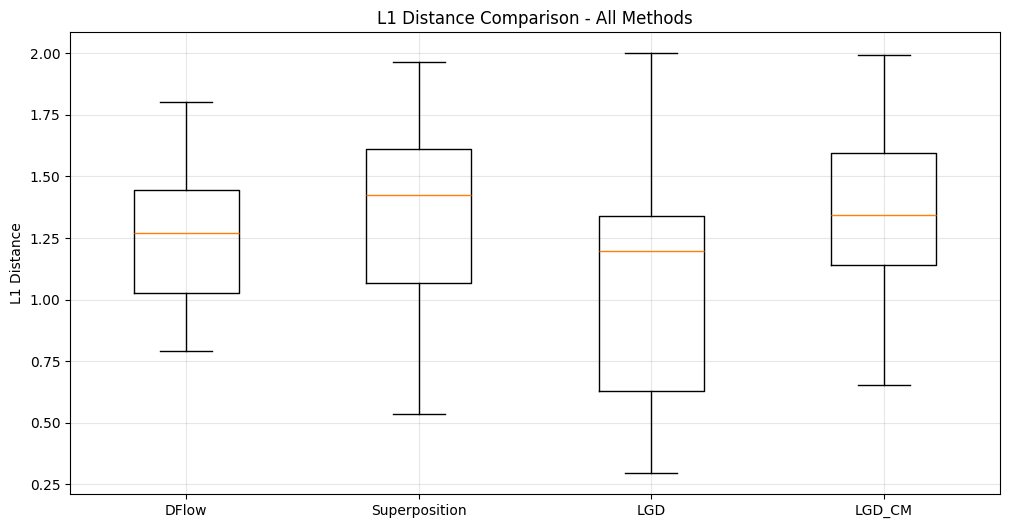

In [24]:
import matplotlib.pyplot as plt

# change
# Create boxplot for all four distance lists
data = [l1_distance_dflow_list, l1_distance_superposition_list, l1_distance_LGD_list, l1_distance_LGD_CM_list]
data = [[l.detach().numpy() for l in dist_list]  for dist_list in  data]
print(data)
labels = ['DFlow', 'Superposition', 'LGD', 'LGD_CM']

plt.figure(figsize=(12, 6))
plt.boxplot(data, labels=labels)
plt.ylabel('L1 Distance')
plt.title('L1 Distance Comparison - All Methods')
plt.grid(True, alpha=0.3)
plt.show()
# changed

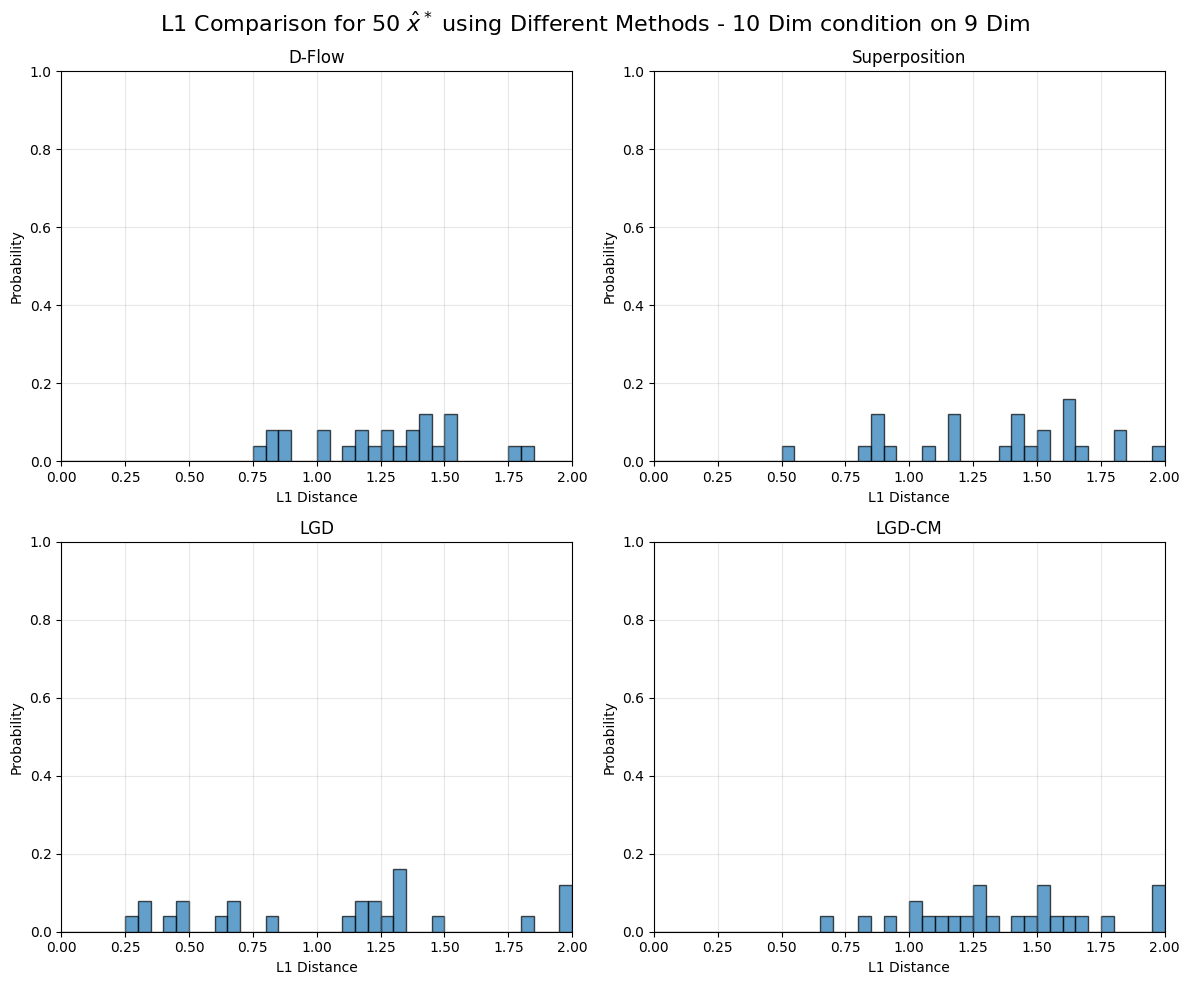

In [49]:
import matplotlib.pyplot as plt
import numpy as np

# Your data
data = [l1_distance_dflow_list, l1_distance_superposition_list, l1_distance_LGD_list, l1_distance_LGD_CM_list]
data = [[l.detach().numpy() for l in dist_list] for dist_list in data]

# Method names for titles
method_names = ['D-Flow', 'Superposition', 'LGD', 'LGD-CM']

# Create subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()  # Make it easier to iterate

# Plot histograms
for i, (distances, method_name) in enumerate(zip(data, method_names)):
    # Flatten the list of arrays if needed
    flat_distances = np.concatenate([np.array(d).flatten() for d in distances])

    # Create bins every 0.05 from 0 to 2
    bins = np.arange(0, 2.05, 0.05)  # 0.05 to include 2.0

    # Calculate histogram with probability (weights sum to 1)
    weights = np.ones_like(flat_distances) / len(flat_distances)
    axes[i].hist(flat_distances, bins=bins, alpha=0.7, edgecolor='black', weights=weights)
    axes[i].set_title(f'{method_name}')
    axes[i].set_xlabel('L1 Distance')
    axes[i].set_ylabel('Probability')
    axes[i].set_xlim(0, 2)
    axes[i].set_ylim(0, 1)
    axes[i].grid(True, alpha=0.3)



# Add main title
fig.suptitle(r'L1 Comparison for 50 $\hat{x}^*$ using Different Methods - 10 Dim condition on 9 Dim', fontsize=16)

plt.tight_layout()
plt.show()


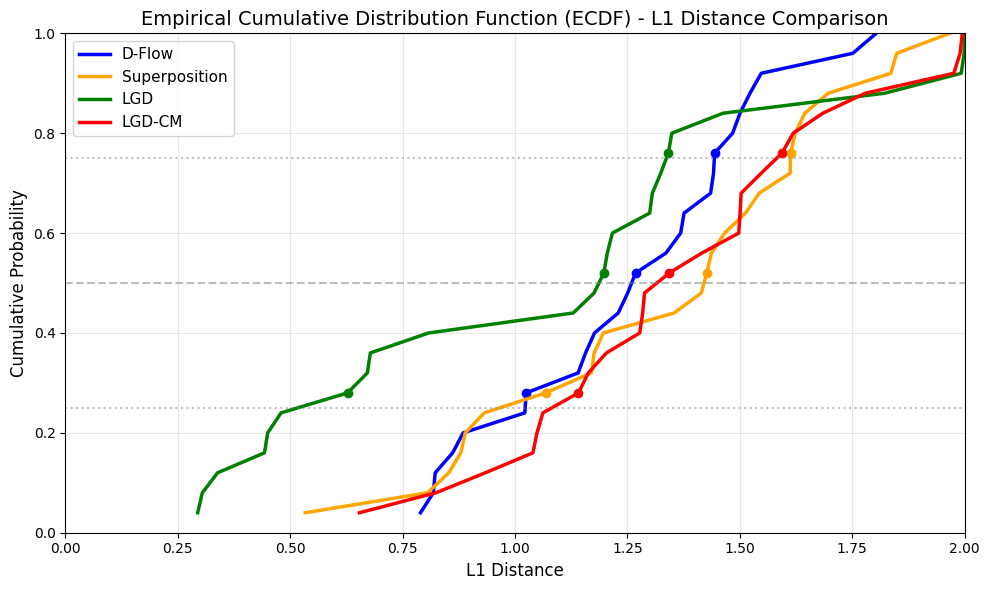

In [26]:
# Create ECDF plot
plt.figure(figsize=(10, 6))
colors = ['blue', 'orange', 'green', 'red']

for i, (distances, method_name, color) in enumerate(zip(data, method_names, colors)):
    # Flatten the list of arrays if needed
    flat_distances = np.concatenate([np.array(d).flatten() for d in distances])

    # Sort the data
    sorted_data = np.sort(flat_distances)
    # Calculate ECDF values
    ecdf_y = np.arange(1, len(sorted_data) + 1) / len(sorted_data)

    plt.plot(sorted_data, ecdf_y, label=method_name, color=color, linewidth=2.5)

    # Add markers at quartiles for better readability
    quartiles = [0.25, 0.5, 0.75]
    for q in quartiles:
        idx = int(q * len(sorted_data))
        plt.plot(sorted_data[idx], ecdf_y[idx], 'o', color=color, markersize=6)

plt.xlabel('L1 Distance', fontsize=12)
plt.ylabel('Cumulative Probability', fontsize=12)
plt.title('Empirical Cumulative Distribution Function (ECDF) - L1 Distance Comparison', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.xlim(0, 2)
plt.ylim(0, 1)

# Add reference lines
plt.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='Median (50%)')
plt.axhline(y=0.25, color='gray', linestyle=':', alpha=0.5)
plt.axhline(y=0.75, color='gray', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

/tmp/ipython-input-4163520019.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(time_data, labels=time_labels, patch_artist=True)


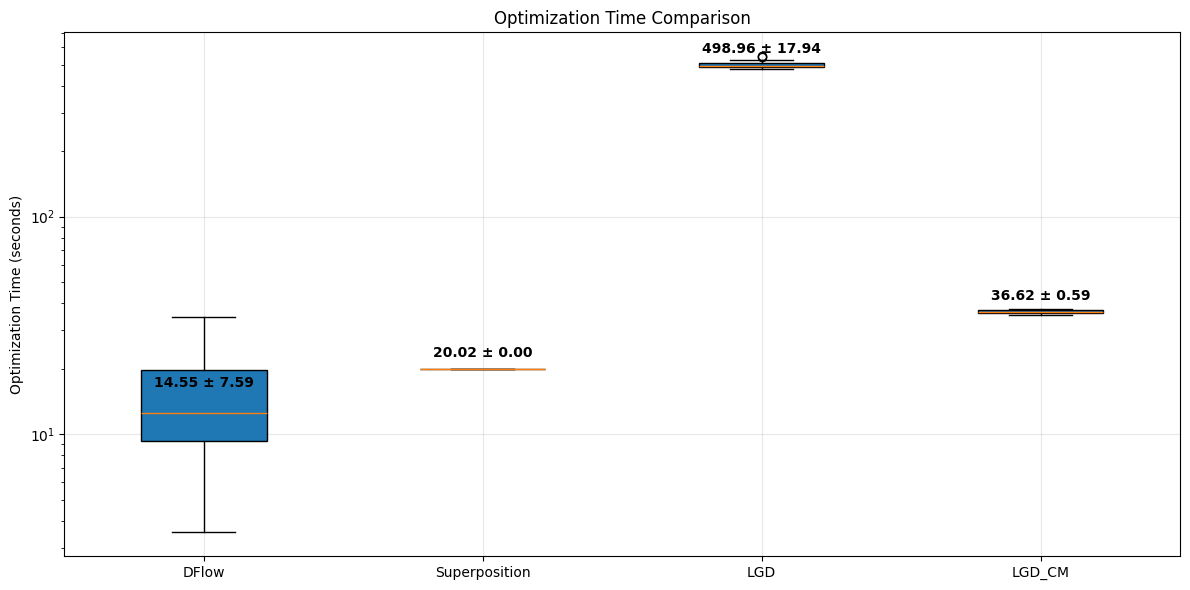

In [55]:
import numpy as np
import matplotlib.pyplot as plt

# Example time data (replace with your own)
time_data = [dflow_times, superposition_times, lgd_times, lgd_cm_times]
time_labels = ['DFlow', 'Superposition', 'LGD', 'LGD_CM']

# Compute mean and std for each method
means = [np.mean(times) for times in time_data]
stds = [np.std(times) for times in time_data]

# Create boxplot
plt.figure(figsize=(12, 6))
plt.boxplot(time_data, labels=time_labels, patch_artist=True)
plt.ylabel('Optimization Time (seconds)')
plt.title('Optimization Time Comparison')
plt.yscale('log')  # Log scale for better visualization
plt.grid(True, alpha=0.3)

# Annotate mean ± std a little higher above each box
for i, (mean, std) in enumerate(zip(means, stds), start=1):
    y_pos = mean * 1.1  # Shift text higher (30% above mean)
    plt.text(i, y_pos, f"{mean:.2f} ± {std:.2f}",
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


In [28]:
import torch
import numpy as np
import pandas as pd
import pickle

def to_numpy(x):
    """Convert tensor/numpy to numpy array - handles gradients properly"""
    if torch.is_tensor(x):
        return x.detach().cpu().numpy()
    return np.array(x)

def to_list(x_list):
    """Convert list of tensors/numpy to list of floats - fixed gradient handling"""
    result = []
    for x in x_list:
        x_np = to_numpy(x)  # Use our safe to_numpy function
        if x_np.size == 1:
            result.append(float(x_np))
        else:
            result.append(x_np.tolist())
    return result

def save_model_safely(model, model_name):
    """Safely save a model - handles different model types and pickling issues"""
    if model is None:
        return None

    try:
        # Test if the model can be pickled
        pickle.dumps(model)

        # If pickling works, save the full model
        if hasattr(model, 'state_dict'):
            model_data = {
                'type': 'pytorch_model',
                'state_dict': model.state_dict(),
                'model_class': model.__class__.__name__,
                'model_object': model,
                'picklable': True
            }
        else:
            model_data = {
                'type': 'other_model',
                'model_object': model,
                'model_class': model.__class__.__name__,
                'picklable': True
            }

        return model_data

    except Exception as e:
        # If pickling fails, save only the state_dict for PyTorch models
        try:
            if hasattr(model, 'state_dict'):
                model_data = {
                    'type': 'pytorch_model',
                    'state_dict': model.state_dict(),
                    'model_class': model.__class__.__name__,
                    'model_object': None,  # Can't pickle the full model
                    'picklable': False,
                    'error': str(e)
                }
                return model_data
            else:
                # For non-PyTorch models that can't be pickled, save basic info
                model_data = {
                    'type': 'unpicklable_model',
                    'model_class': model.__class__.__name__,
                    'model_object': None,
                    'picklable': False,
                    'error': str(e)
                }
                return model_data
        except Exception as e2:
            return {
                'type': 'failed_model',
                'model_class': 'unknown',
                'picklable': False,
                'error': f"Complete failure: {str(e2)}"
            }

# Store all data including models
data = {
    'x_star': to_numpy(x_star).tolist(),

    # Results (converted to lists)
    'results': {
        'DFlow': [to_numpy(x).tolist() for x in best_x_t_dflow_list],
        'Superposition': [to_numpy(x).tolist() for x in best_x_t_superposition_list],
        'LGD': [to_numpy(x).tolist() for x in best_x_t_LGD_list],
        'LGD_CM': [to_numpy(x).tolist() for x in best_x_t_LGD_CM_list]
    },

    # Pre-calculated distances (converted to simple lists)
    'distances': {
        'DFlow_L1': to_list(l1_distance_dflow_list),
        'Superposition_L1': to_list(l1_distance_superposition_list),
        'LGD_L1': to_list(l1_distance_LGD_list),
        'LGD_CM_L1': to_list(l1_distance_LGD_CM_list),
    },

    # Times
    'times': {
        'DFlow': float(dflow_times[0]) if 'dflow_times' in globals() and len(dflow_times) > 0 else None,
        'Superposition': float(superposition_times[0]) if 'superposition_times' in globals() and len(superposition_times) > 0 else None,
        'LGD': float(lgd_times[0]) if 'lgd_times' in globals() and len(lgd_times) > 0 else None,
        'LGD_CM': float(lgd_cm_times[0]) if 'lgd_cm_times' in globals() and len(lgd_cm_times) > 0 else None
    },

    # 🔥 MODELS - Save all your models here
    'models': {}
}

print("💾 SAVING MODELS...")

# Save all your models
models_to_save = {
    'superposition_cond_diff': model_cond_diff if 'model_cond_diff' in globals() else None,
    'consistency_model': Cos_model if 'Cos_model' in globals() else None,
    'LGD_conditional': model_cond if 'model_cond' in globals() else None,
    'LGD_unconditional': model_uncond if 'model_uncond' in globals() else None,
    # 'flow_conditional': vf_y_cond_x if 'vf_y_cond_x' in globals() else None,
    # 'flow_unconditional': vf_X if 'vf_X' in globals() else None
}

for model_name, model in models_to_save.items():
    data['models'][model_name] = save_model_safely(model, model_name)

# Calculate additional L1/L2 distances if needed
x_star_flat = to_numpy(x_star).flatten()
for method, x_list in zip(['DFlow', 'Superposition', 'LGD', 'LGD_CM'],
                         [best_x_t_dflow_list, best_x_t_superposition_list, best_x_t_LGD_list, best_x_t_LGD_CM_list]):
    if f'{method}_L2' not in data['distances']:
        data['distances'][f'{method}_L2'] = [float(np.linalg.norm(to_numpy(x).flatten() - x_star_flat, ord=2)) for x in x_list]

# Save everything
with open('experiment_data_with_models.pkl', 'wb') as f:
    pickle.dump(data, f)

# Save distances to CSV
pd.DataFrame(dict([(k, pd.Series(v)) for k, v in data['distances'].items()])).to_csv('distances.csv')

print("✅ Data and models saved to experiment_data_with_models.pkl")

# Show what was saved successfully
saved_models = [(name, model_data) for name, model_data in data['models'].items() if model_data is not None]
picklable_models = [name for name, model_data in saved_models if model_data.get('picklable', False)]
unpicklable_models = [name for name, model_data in saved_models if not model_data.get('picklable', True)]

if picklable_models:
    print(f"🤖 Full models saved: {', '.join(picklable_models)}")
if unpicklable_models:
    print(f"⚠️  State dicts only: {', '.join(unpicklable_models)} (models couldn't be pickled)")

💾 SAVING MODELS...
✅ Data and models saved to experiment_data_with_models.pkl
🤖 Full models saved: superposition_cond_diff, LGD_conditional, LGD_unconditional
⚠️  State dicts only: consistency_model (models couldn't be pickled)


In [29]:
# import pickle

# # Load data
# with open('experiment_data_with_models.pkl', 'rb') as f:
#     data = pickle.load(f)

# # Extract models to their original variable names
# model_cond_diff = data['models']['superposition_cond_diff']['model_object'] if data['models']['superposition_cond_diff'] and data['models']['superposition_cond_diff'].get('picklable') else None
# Cos_model = data['models']['consistency_model']['model_object'] if data['models']['consistency_model'] and data['models']['consistency_model'].get('picklable') else None
# model_cond = data['models']['LGD_conditional']['model_object'] if data['models']['LGD_conditional'] and data['models']['LGD_conditional'].get('picklable') else None
# model_uncond = data['models']['LGD_unconditional']['model_object'] if data['models']['LGD_unconditional'] and data['models']['LGD_unconditional'].get('picklable') else None
# # vf_y_cond_x = data['models']['flow_conditional']['model_object'] if data['models']['flow_conditional'] and data['models']['flow_conditional'].get('picklable') else None
# # vf_X = data['models']['flow_unconditional']['model_object'] if data['models']['flow_unconditional'] and data['models']['flow_unconditional'].get('picklable') else None

# # Extract other data
# x_star = data['x_star']
# distances = data['distances']
# times = data['times']

#Super Position - analysis of number of conditions

### Train

In [30]:
# Flip the values for superposition
point_l = [p.flip(0) for p in mu_list]
mu_list_super = point_l
idx = torch.arange(Sigma_list[0].size(0) - 1, -1, -1)
Sigma_list_super = [s[idx][:, idx]  for s in Sigma_list]# [.T for sigma in Sigma_list]


nfeatures= mu_list[0].shape[0]
condition_on=1

# Train
model_cond_diff =DiffusionGeneral.DiffusionModel(nfeatures=nfeatures, nblocks=nblocks, nunits=nunits, condition=True,condition_on=condition_on,diffusion_steps=diffusion_steps)
model_cond_diff.train_model( data_generator=partial(dist_utils.generate_mog_samples, xi=mu_list_super, S=Sigma_list_super, beta=alpha, kernel_func=None),dataloader=None, num_iterations=nepochs)


100%|██████████| 30000/30000 [35:20<00:00, 14.15it/s, loss=0.525]


In [31]:
mu_list, Sigma_list, alpha,mog_means, mog_variances,weights,x_star= dist_utils.get_param_mog_with_target(dim_data=10,num_components=4,device='cpu',conditional_modes=2,distanceOrScale="Distance")
mog_means, mog_variances, weights= dist_utils.filter_and_normalize(mog_means, mog_variances, weights, threshold=0.001)


In [32]:
n_sample=n_attemp_optim=500
first_value = mog_means[0].item()
second_value = mog_means[1].item()
cond1= torch.tensor([first_value],device=device)
cond2= torch.tensor([second_value],device=device)

start_time = time.time()
cond_l= [cond1,cond2]
x_gen_iso,_=  superposition_utils.generate_isosurface_samples(model_cond_diff, cond_l=cond_l,bs=n_sample,device=device)
X_gen_np = x_gen_iso[:, -1, :].detach().cpu().numpy()
end_time = time.time()


superposition_times_cond2 = [end_time - start_time] *n_attemp_optim


# Flip again
X_gen_np_original = torch.tensor(X_gen_np)[:,condition_on:]
X_gen_np_original=X_gen_np_original.flip(1)


  0%|          | 0/1000 [00:00<?, ?it/s]

In [33]:
X_gen_np_original

tensor([[ -5.5561,   1.0858,   0.5276,  ...,  -3.0535,   3.7823,   0.1878],
        [ -4.1773,  -0.8556,   0.1009,  ...,   2.0110,  -1.2250,  -8.0850],
        [ -5.4121,  -0.2654,   1.6837,  ...,  -2.8583,  -0.8044,  -9.4819],
        ...,
        [  2.2204,  -2.5145,  -3.3355,  ...,  -4.8350,   0.0353, -10.4026],
        [ -1.0453,   1.4387,  -0.5175,  ...,  -1.1038,   1.7007,  -9.5057],
        [ -4.1903,   1.2073,   3.0973,  ...,   2.6015,  -2.2477,  -4.1712]])

[tensor([[ -5.5561],
        [  1.0858],
        [  0.5276],
        [-12.5350],
        [ -2.2372],
        [ -0.6444],
        [ -3.0535],
        [  3.7823],
        [  0.1878]]), tensor([[-4.1773],
        [-0.8556],
        [ 0.1009],
        [-6.2121],
        [ 1.2386],
        [ 1.7226],
        [ 2.0110],
        [-1.2250],
        [-8.0850]]), tensor([[-5.4121],
        [-0.2654],
        [ 1.6837],
        [-3.1590],
        [ 3.2644],
        [ 3.7588],
        [-2.8583],
        [-0.8044],
        [-9.4819]]), tensor([[-3.5868],
        [-9.0294],
        [13.3215],
        [ 1.8645],
        [ 9.3894],
        [-9.1908],
        [ 8.1485],
        [-0.6208],
        [-6.0229]]), tensor([[-4.7324],
        [-3.8791],
        [-1.0978],
        [-6.9186],
        [ 2.3765],
        [ 4.6938],
        [ 1.2777],
        [-4.8907],
        [-9.2056]]), tensor([[ -2.5304],
        [  6.8248],
        [  1.2963],
        [-14.3108],
        [  7.0797],
        [  3.4937],
     

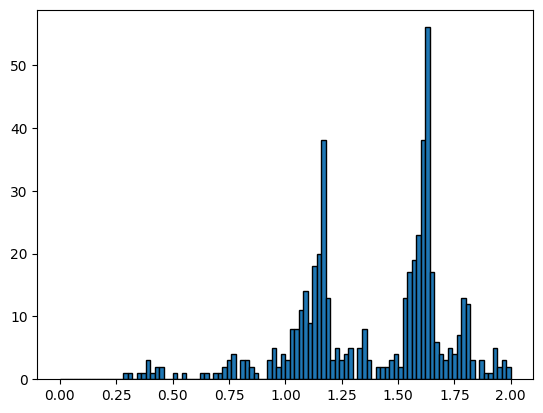

In [34]:
l1_distance_superposition_list_2cond=[]
best_x_t_superposition_list_2cond=[]
for i in range(X_gen_np_original.shape[0]):
   val = X_gen_np_original[i:i+1].reshape(-1, 1)
   l1_distance = dist_utils.warpper_L1_distance(val, mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
   l1_distance_superposition_list_2cond.append(l1_distance )
   best_x_t_superposition_list_2cond.append(val)


print(best_x_t_superposition_list_2cond)
print(l1_distance_superposition_list_2cond)

plt.hist(l1_distance_superposition_list_2cond,  edgecolor='black',range=(0,2),bins=100,)
plt.show()


In [35]:
mog_means

tensor([[[-2.8153]],

        [[ 1.1829]]], dtype=torch.float64)

In [36]:
n_sample=n_attemp_optim=500
first_value = mog_means[0].item()
second_value = mog_means[1].item()
cond1= torch.tensor([first_value],device=device)
cond2= torch.tensor([second_value],device=device)
cond3= torch.tensor([first_value+0.2],device=device)

start_time = time.time()
cond_l= [cond1,cond2,cond3]
x_gen_iso,_=  superposition_utils.generate_isosurface_samples(model_cond_diff, cond_l=cond_l,bs=n_sample,device=device)
X_gen_np = x_gen_iso[:, -1, :].detach().cpu().numpy()
end_time = time.time()


superposition_times_cond3 = [end_time - start_time] *n_attemp_optim


# Flip again
X_gen_np_original = torch.tensor(X_gen_np)[:,condition_on:]
X_gen_np_original=X_gen_np_original.flip(1)


  0%|          | 0/1000 [00:00<?, ?it/s]

[tensor([[ -1.9469],
        [  4.5155],
        [  2.4499],
        [-10.5073],
        [  4.3100],
        [  0.8208],
        [  5.5192],
        [ -1.1473],
        [ -7.4804]]), tensor([[ 0.4037],
        [ 6.6582],
        [ 6.4764],
        [-9.6472],
        [ 6.4632],
        [-0.1112],
        [-1.3434],
        [-3.0668],
        [-2.6024]]), tensor([[ -5.2877],
        [  0.9330],
        [  0.2356],
        [-10.3876],
        [  1.9933],
        [ -3.2279],
        [  5.5180],
        [ -2.0018],
        [ -5.4398]]), tensor([[ -3.9653],
        [  0.5674],
        [  2.1452],
        [ -6.7845],
        [ -1.0634],
        [ -8.2338],
        [ -0.8748],
        [  3.9026],
        [-12.8289]]), tensor([[ -5.8323],
        [  2.8003],
        [ -5.5813],
        [-15.0424],
        [ -0.3645],
        [ -1.0909],
        [  5.7947],
        [ -1.0112],
        [ -3.2354]]), tensor([[-7.5373],
        [ 1.8218],
        [ 6.0146],
        [-9.0335],
        [ 5.2203],
   

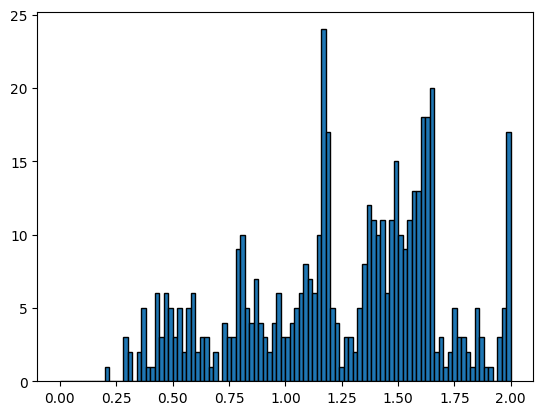

In [37]:
best_x_t_superposition_list_3cond=[]
l1_distance_superposition_list_3cond=[]
for i in range(X_gen_np_original.shape[0]):
   val = X_gen_np_original[i:i+1].reshape(-1, 1)
   l1_distance = dist_utils.warpper_L1_distance(val, mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
   l1_distance_superposition_list_3cond.append(l1_distance )
   best_x_t_superposition_list_3cond.append(val)


print(best_x_t_superposition_list_3cond)
print(l1_distance_superposition_list_3cond)

plt.hist(l1_distance_superposition_list_3cond,  edgecolor='black',range=(0,2),bins=100,)
plt.show()


In [38]:
n_sample=n_attemp_optim=500
first_value = mog_means[0].item()
second_value = mog_means[1].item()
cond1= torch.tensor([first_value],device=device)
cond2= torch.tensor([second_value],device=device)
cond3= torch.tensor([first_value+0.2],device=device)
cond4= torch.tensor([second_value-0.1],device=device)

start_time = time.time()
cond_l= [cond1,cond2,cond3,cond4]
x_gen_iso,_=  superposition_utils.generate_isosurface_samples(model_cond_diff, cond_l=cond_l,bs=n_sample,device=device)
X_gen_np = x_gen_iso[:, -1, :].detach().cpu().numpy()
end_time = time.time()


superposition_times_cond4 = [end_time - start_time] *n_attemp_optim


# Flip again
X_gen_np_original = torch.tensor(X_gen_np)[:,condition_on:]
X_gen_np_original=X_gen_np_original.flip(1)


  0%|          | 0/1000 [00:00<?, ?it/s]

[tensor([[ -2.1194],
        [  4.9953],
        [  0.3220],
        [-10.5803],
        [  3.2687],
        [  0.2724],
        [ -3.4455],
        [ -0.6831],
        [ -3.9981]]), tensor([[ -5.3488],
        [  1.9618],
        [ -1.9696],
        [-12.7023],
        [  0.9842],
        [  0.2169],
        [  5.0972],
        [ -0.0961],
        [ -4.0397]]), tensor([[-2.8828],
        [-6.0429],
        [ 3.8117],
        [-5.5208],
        [ 0.7109],
        [ 0.1555],
        [ 2.0412],
        [-0.3337],
        [-7.4021]]), tensor([[ -3.5676],
        [ -2.3977],
        [  8.0737],
        [ -4.2927],
        [ -0.4207],
        [ -6.9618],
        [  0.2498],
        [  2.4817],
        [-12.2136]]), tensor([[-5.2901],
        [ 1.1612],
        [ 0.3993],
        [-9.6917],
        [ 1.4214],
        [-1.1834],
        [ 2.0682],
        [-1.4821],
        [-4.7322]]), tensor([[ -2.7099],
        [  4.0302],
        [  1.9096],
        [-10.4265],
        [  4.3608],
       

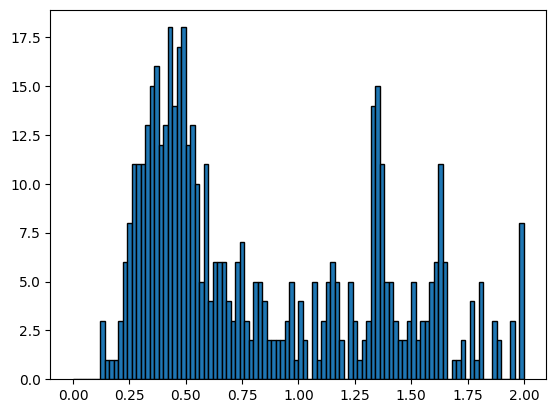

In [39]:
best_x_t_superposition_list_4cond=[]
l1_distance_superposition_list_4cond=[]
for i in range(X_gen_np_original.shape[0]):
   val = X_gen_np_original[i:i+1].reshape(-1, 1)
   l1_distance = dist_utils.warpper_L1_distance(val, mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
   l1_distance_superposition_list_4cond.append(l1_distance )
   best_x_t_superposition_list_4cond.append(val)


print(best_x_t_superposition_list_4cond)
print(l1_distance_superposition_list_4cond)

plt.hist(l1_distance_superposition_list_4cond,  edgecolor='black',range=(0,2),bins=100,)
plt.show()


In [40]:
n_sample=n_attemp_optim=500
first_value = mog_means[0].item()
second_value = mog_means[1].item()
cond1= torch.tensor([first_value],device=device)
cond2= torch.tensor([second_value],device=device)
cond3= torch.tensor([first_value+0.2],device=device)
cond4= torch.tensor([second_value-0.1],device=device)
cond5= torch.tensor([second_value+0.3],device=device)

start_time = time.time()
cond_l= [cond1,cond2,cond3,cond4,cond5]
x_gen_iso,_=  superposition_utils.generate_isosurface_samples(model_cond_diff, cond_l=cond_l,bs=n_sample,device=device)
X_gen_np = x_gen_iso[:, -1, :].detach().cpu().numpy()
end_time = time.time()


superposition_times_cond5 = [end_time - start_time] *n_attemp_optim


# Flip again
X_gen_np_original = torch.tensor(X_gen_np)[:,condition_on:]
X_gen_np_original=X_gen_np_original.flip(1)


  0%|          | 0/1000 [00:00<?, ?it/s]

[tensor([[-4.0243],
        [ 3.4150],
        [ 1.7983],
        [-9.2687],
        [ 3.6575],
        [-0.9881],
        [ 2.9328],
        [-1.3747],
        [-6.1504]]), tensor([[ -9.1593],
        [  1.9648],
        [-25.7314],
        [ -3.0787],
        [  6.0802],
        [  7.8676],
        [-31.2610],
        [  4.0481],
        [  2.7120]]), tensor([[ -3.7677],
        [  3.2364],
        [  1.7544],
        [-10.9417],
        [  4.4736],
        [ -0.2889],
        [  4.0489],
        [ -1.2024],
        [ -4.8056]]), tensor([[ -35.8341],
        [ -70.5686],
        [  -3.9259],
        [  20.2038],
        [ 137.0589],
        [ 145.0990],
        [-140.1426],
        [  64.0205],
        [ -37.0555]]), tensor([[ -5.4446],
        [  0.4976],
        [  1.1630],
        [-11.6486],
        [  0.2654],
        [ -4.7248],
        [  6.3934],
        [ -1.8270],
        [ -3.9913]]), tensor([[ -2.5680],
        [  4.6176],
        [  0.3994],
        [-12.6947],
        [

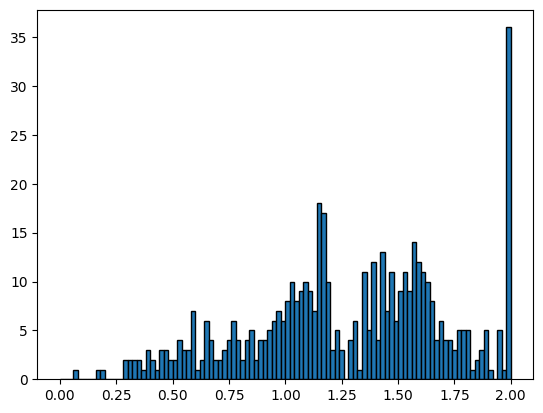

In [41]:
best_x_t_superposition_list_5cond=[]
l1_distance_superposition_list_5cond=[]
for i in range(X_gen_np_original.shape[0]):
   val = X_gen_np_original[i:i+1].reshape(-1, 1)
   l1_distance = dist_utils.warpper_L1_distance(val, mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
   l1_distance_superposition_list_5cond.append(l1_distance )
   best_x_t_superposition_list_5cond.append(val)


print(best_x_t_superposition_list_5cond)
print(l1_distance_superposition_list_5cond)

plt.hist(l1_distance_superposition_list_5cond,  edgecolor='black',range=(0,2),bins=100,)
plt.show()


L1 Distance Statistics (Filtered 0 ≤ x ≤ 2):


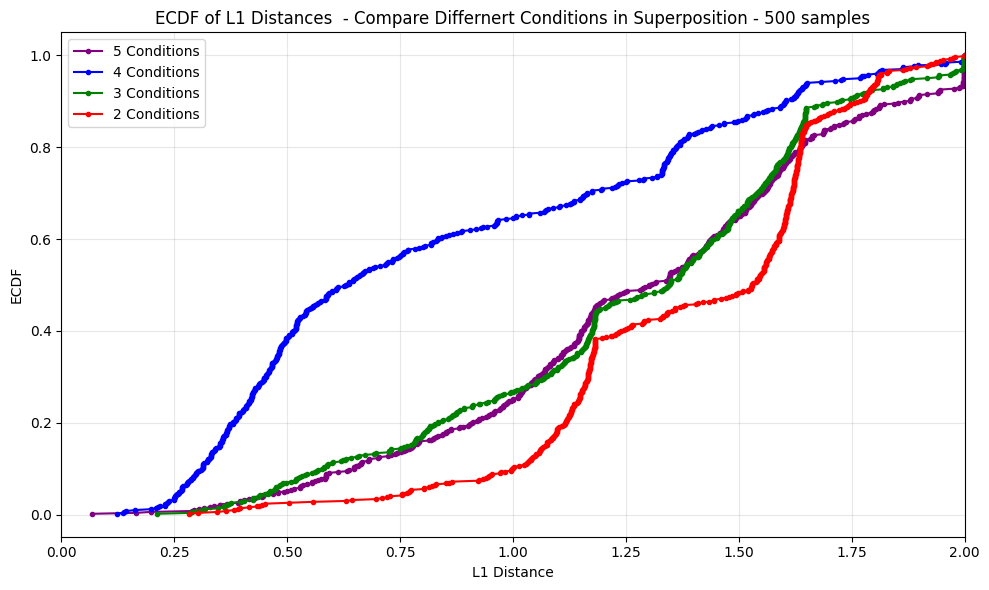

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Updated lists with Condition 5
lists = [
    l1_distance_superposition_list_5cond,
    l1_distance_superposition_list_4cond,
    l1_distance_superposition_list_3cond,
    l1_distance_superposition_list_2cond
]

labels = ["5 Conditions", "4 Conditions", "3 Conditions", "2 Conditions"]
colors = ['purple', 'blue', 'green', 'red']

# Filter each list to include values between 0 and 2
arrays = [
    np.array([float(x) for x in lst if 0 <= float(x) <= 2], dtype=np.float32)
    for lst in lists
]

# Compute stats
means = [np.mean(arr) for arr in arrays]
medians = [np.median(arr) for arr in arrays]
stds = [np.std(arr) for arr in arrays]

# Create and print the table
df_l1 = pd.DataFrame({
    "Condition": labels,
    "Mean": means,
    "Median": medians,
    "Std": stds
})
print("L1 Distance Statistics (Filtered 0 ≤ x ≤ 2):")

# Plot ECDF
plt.figure(figsize=(10, 6))
for arr, label, color in zip(arrays, labels, colors):
    sorted_arr = np.sort(arr)
    ecdf = np.arange(1, len(sorted_arr) + 1) / len(sorted_arr)
    plt.plot(sorted_arr, ecdf, marker='.', linestyle='-', label=label, color=color)

plt.xlabel('L1 Distance')
plt.ylabel('ECDF')
plt.title('ECDF of L1 Distances  - Compare Differnert Conditions in Superposition - 500 samples')
plt.grid(True, alpha=0.3)
plt.xlim(0, 2)
plt.legend()
plt.tight_layout()
plt.show()


In [43]:
# Time data (no filtering)
time_lists = [
    superposition_times_cond5,
    superposition_times_cond4,
    superposition_times_cond3,
    superposition_times_cond2
]

time_labels = ["5 Conditions", "4 Conditions", "3 Conditions", "2 Conditions"]

# Convert to NumPy arrays
arrays = [np.array([float(x) for x in lst], dtype=np.float32) for lst in time_lists]

# Compute stats
means = [np.mean(arr) for arr in arrays]
medians = [np.median(arr) for arr in arrays]
stds = [np.std(arr) for arr in arrays]

# Create and print table
df_time = pd.DataFrame({
    "Condition": time_labels,
    "Mean (s)": means,
    "Median (s)": medians,
    "Std (s)": stds
})
df_time

,Condition,Mean (s),Median (s),Std (s)
0,5 Conditions,176.158722,176.158722,0.000000
1,4 Conditions,139.160400,139.160416,0.000015
2,3 Conditions,104.591560,104.591560,0.000000
3,2 Conditions,71.384468,71.384468,0.000000


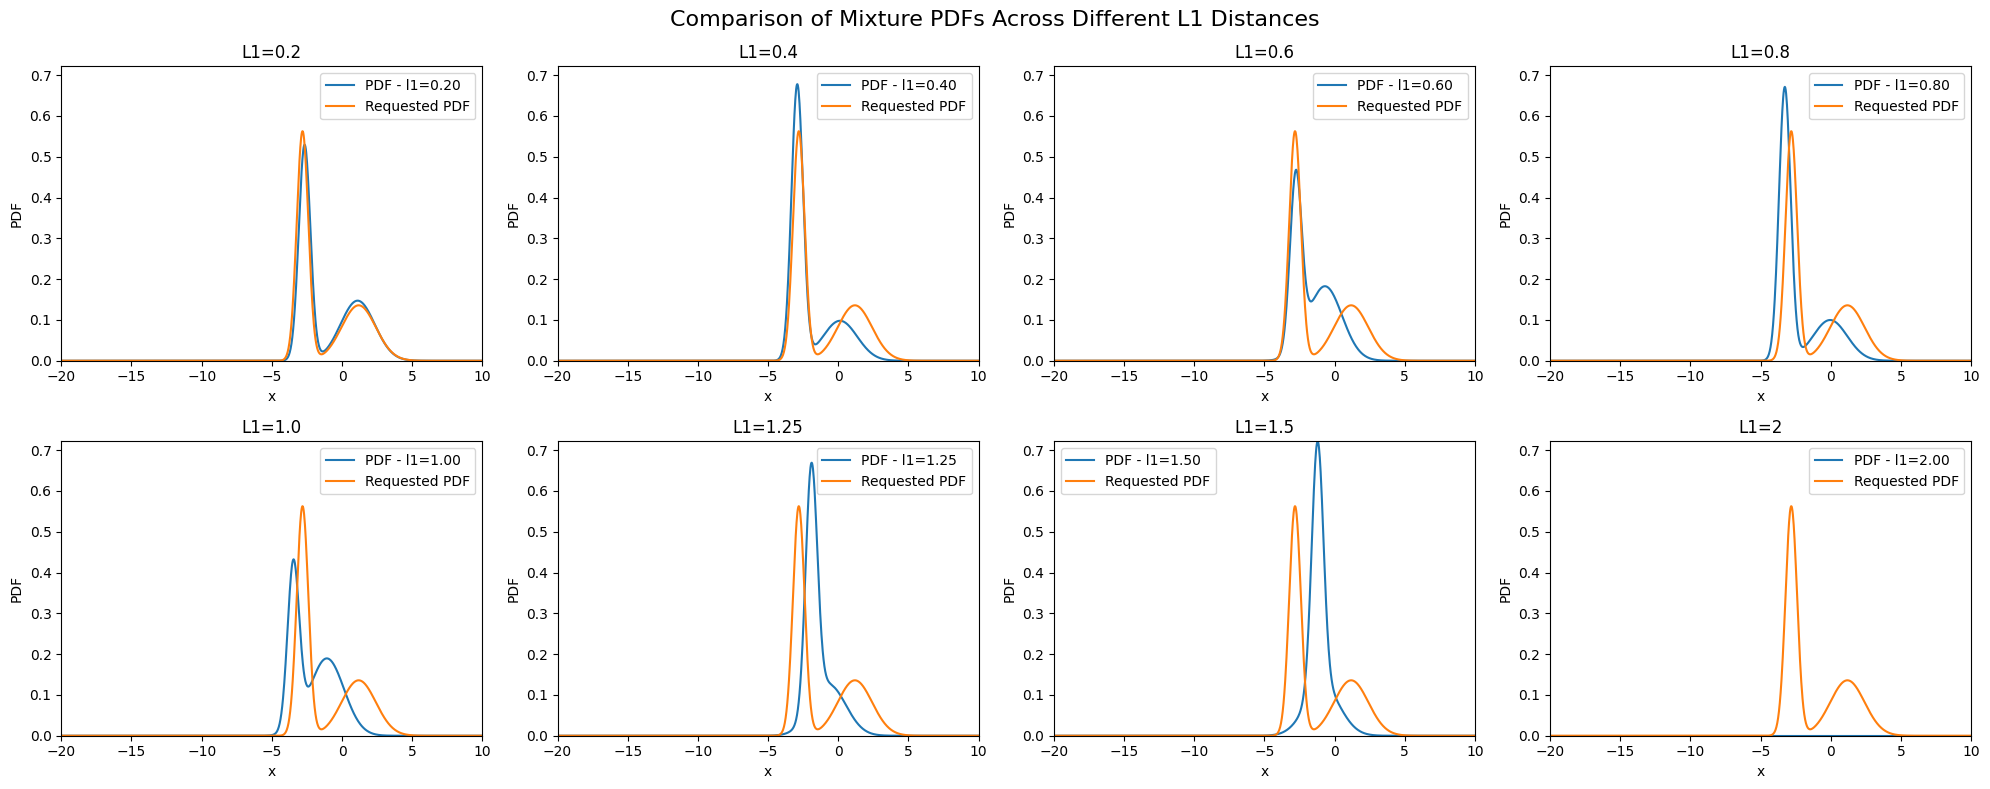

In [45]:
import matplotlib.pyplot as plt
import torch
import numpy as np

# Step 1: Convert l1 distances to regular numbers
l1_distances = [l.detach().cpu().item() for l in l1_distance_superposition_list_5cond]

# Step 2: Define target values and find closest indices
targets = [0.2, 0.4, 0.6, 0.8, 1., 1.25, 1.5, 2]
closest_indices = [np.argmin([abs(d - t) for d in l1_distances]) for t in targets]

# Step 3: Prepare x-axis values for PDF plots
x_vals = torch.linspace(-20, 10, 1000).unsqueeze(1)  # shape [1000, 1]

# Step 4: Create subplots
fig, axs = plt.subplots(2, 4, figsize=(20, 8))
axs = axs.flatten()

all_x = []
all_y = []

# Step 5: Iterate through each index, compute PDFs, and store values
for i, idx in enumerate(closest_indices):
    best_sample = best_x_t_superposition_list_5cond[idx]

    # Compute conditional distribution
    mu_temp, Sigma_temp = dist_utils.compute_conditionals(mu_list, Sigma_list, best_sample)
    temp_alpha = dist_utils.compute_alpha(mu_list, Sigma_list, alpha, best_sample)

    means_best = [m.view(-1) for m in mu_temp]
    covariances_best = [c.view(-1) for c in Sigma_temp]
    temp_alpha_best = temp_alpha.squeeze()

    # Compute PDFs
    pdf_val_good = dist_utils.mog_multivariate_pdf(x_vals, means_best, covariances_best, temp_alpha_best, log=False)
    pdf_vals_requested = dist_utils.mog_multivariate_pdf(x_vals, mog_means, mog_variances, weights, log=False)

    # Move to CPU for plotting
    pdf_val_good = pdf_val_good.detach().cpu().numpy()
    pdf_vals_requested = pdf_vals_requested.detach().cpu().numpy()
    x_vals_np = x_vals.squeeze(1).cpu().numpy()

    # Store for global min/max calculation
    all_x.append(x_vals_np)
    all_y.append(pdf_val_good)
    all_y.append(pdf_vals_requested)

    # Plot
    axs[i].plot(x_vals_np, pdf_val_good, label=f"PDF - l1={targets[i]:.2f}")
    axs[i].plot(x_vals_np, pdf_vals_requested, label="Requested PDF")
    axs[i].legend()
    axs[i].set_title(f"L1={targets[i]}")
    axs[i].set_xlabel("x")
    axs[i].set_ylabel("PDF")

# Step 6: Set same x/y limits for all subplots
x_min, x_max = np.min(all_x), np.max(all_x)
y_min, y_max = np.min(all_y), np.max(all_y)

for ax in axs:
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

plt.suptitle("Comparison of Mixture PDFs Across Different L1 Distances", fontsize=16)
plt.tight_layout()
plt.show()
